# 05 · Evidencia, caso de negocio y recomendación (Sección E)

> **Pregunta:** ¿Qué mercados crecieron en volumen y, de esos, cuáles dejaron buen margen y cuáles crecieron dejando poco?

Este cuaderno **no recalcula la métrica**: ejecuta completo el cuaderno `04_metrica_sensibilidad.ipynb` y usa sus resultados (`fact_export`, `margen_a`, `cruce`, `comp`). Así las cifras de la Sección E son, por construcción, las mismas de la ficha de la métrica (Sección D).

Criterios heredados del cuaderno 04:

| Concepto | Definición |
|:---|:---|
| Métrica | Margen bruto por litro = (Σ ingreso neto CLP − Σ costo de producto CLP) / Σ litros |
| Conversión | Dólar observado a la **fecha de la factura** (Definición A) |
| Universo | Ventas de exportación 2025 (sin Chile) |
| Creció | Litros del 2.º semestre 2025 > litros del 1.er semestre |
| Buen margen | Margen por litro ≥ mediana de los 10 mercados de exportación |


## 0. Ejecutar el cuaderno 04

In [1]:
%%capture salida_04
%run ./04_metrica_sensibilidad.ipynb

In [2]:
# Controles: el cuaderno 04 corrió y entregó lo que esta sección necesita
for nombre in ["fact_export", "margen_a", "cruce", "comp", "dim_producto", "stg_ventas", "fact_venta"]:
    assert nombre in globals(), f"El cuaderno 04 no dejó la variable {nombre}"
assert len(fact_export) == 10_715, len(fact_export)
assert fact_export["ingreso_neto_clp_fecha_venta"].notna().all()
assert fact_export["costo_total_clp"].notna().all()

# Avisos del cuaderno 04 (por ejemplo, si falta el dólar de 2026)
for linea in salida_04.stdout.splitlines():
    if linea.startswith("Aviso") or linea.startswith("Años sin"):
        print(linea)
print(f"\nVentas de exportación 2025: {len(fact_export):,}")
print(f"Mediana del margen por litro: {cruce['margen_por_litro_clp'].median():,.0f} CLP/litro")

Aviso: no se pudo descargar el tipo de cambio de 2024; se usa la copia en tipo_cambio_2024.json.
Aviso: no se pudo descargar el tipo de cambio de 2026; se usa la copia en tipo_cambio_2026.json.

Ventas de exportación 2025: 10,715
Mediana del margen por litro: 2,266 CLP/litro


## 1. Estilo común de los gráficos

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

# Paleta: un color para el resto de los mercados y uno de acento para Brasil.
# Mismo significado en todos los gráficos.
AZUL = "#2a78d6"      # resto de los mercados / Definición A
NARANJA = "#eb6834"   # Brasil
GRIS = "#8a8984"      # referencias / Definición B
TEXTO = "#0b0b0b"
TEXTO_2 = "#52514e"
GRILLA = "#e4e3df"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.edgecolor": GRILLA,
    "axes.labelcolor": TEXTO_2,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlecolor": TEXTO,
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": TEXTO_2,
    "ytick.color": TEXTO_2,
    "grid.color": GRILLA,
    "grid.linewidth": 0.8,
    "figure.dpi": 110,
    "savefig.dpi": 200,
})

FUENTE = (
    "Fuente: ERP comercial (origen_vina.sqlite), costos por producto y añada (origen_costos_productos.csv) "
    "y dólar observado BCCh (mindicador.cl).\nExportación 2025, ingreso neto de descuentos convertido "
    "con el dólar de la fecha de factura; margen antes de flete. Elaboración propia."
)


def num(x, dec=0):
    """Formato chileno: punto de miles y coma decimal."""
    s = f"{x:,.{dec}f}"
    return s.replace(",", "§").replace(".", ",").replace("§", ".")


def pie(fig, texto=FUENTE):
    fig.text(0.01, -0.01, texto, ha="left", va="top", fontsize=7.5, color=TEXTO_2, linespacing=1.4)


miles = FuncFormatter(lambda x, _: num(x))
color_pais = lambda pais: NARANJA if pais == "Brasil" else AZUL

## 2. Tabla base por mercado

Una fila por mercado de exportación con todo lo que usan los gráficos y el caso de negocio. El ingreso bruto y el descuento se pasan a pesos con el mismo dólar de la factura que usa la métrica.

In [4]:
fe = fact_export.copy()
fe["dolar_venta"] = fe["fecha"].map(tasa_por_fecha)
fe["bruto_clp"] = fe["monto_bruto"] * fe["dolar_venta"]
fe["descuento_clp"] = fe["monto_descuento"] * fe["dolar_venta"]
fe["margen_clp"] = fe["ingreso_neto_clp_fecha_venta"] - fe["costo_total_clp"]
fe["trimestre"] = "T" + fe["fecha"].dt.quarter.astype(str)
assert fe["dolar_venta"].notna().all()

por_mercado = (
    fe.groupby("pais")
    .agg(
        litros=("litros", "sum"),
        bruto_clp=("bruto_clp", "sum"),
        descuento_clp=("descuento_clp", "sum"),
        ingreso_clp=("ingreso_neto_clp_fecha_venta", "sum"),
        costo_clp=("costo_total_clp", "sum"),
        margen_clp=("margen_clp", "sum"),
    )
)
por_mercado["margen_litro"] = por_mercado["margen_clp"] / por_mercado["litros"]
por_mercado["descuento_pct"] = por_mercado["descuento_clp"] / por_mercado["bruto_clp"] * 100
por_mercado = por_mercado.join(cruce.set_index("pais")[["crecimiento_pct", "S1", "S2", "cuadrante"]])

# El margen por litro debe ser exactamente el del cuaderno 04
check = por_mercado["margen_litro"] - margen_a.set_index("pais")["margen_por_litro_clp"]
assert check.abs().max() < 1e-6, check

MEDIANA = cruce["margen_por_litro_clp"].median()
por_mercado.sort_values("margen_litro", ascending=False).round(1)

,litros,bruto_clp,descuento_clp,ingreso_clp,costo_clp,margen_clp,margen_litro,descuento_pct,crecimiento_pct,S1,S2,cuadrante
pais,,,,,,,,,,,,
Estados Unidos,"1,115,901.0","5,440,610,138.7","140,586,771.3","5,300,023,367.3","2,694,838,320.0","2,605,185,047.3","2,334.6",2.6,-11.4,"591,606.0","524,295.0",✦ No creció + buen margen
Reino Unido,"1,089,999.0","5,297,058,839.0","138,767,847.7","5,158,290,991.4","2,631,434,940.0","2,526,856,051.4","2,318.2",2.6,0.1,"544,824.0","545,175.0",★ Creció + buen margen
México,"1,096,443.0","5,325,680,254.9","143,005,156.6","5,182,675,098.3","2,647,641,042.0","2,535,034,056.3","2,312.1",2.7,1.7,"543,699.0","552,744.0",★ Creció + buen margen
Japón,"1,124,118.0","5,416,045,940.7","140,595,296.7","5,275,450,644.0","2,697,120,018.0","2,578,330,626.0","2,293.6",2.6,-25.0,"642,501.0","481,617.0",✦ No creció + buen margen
Alemania,"1,095,525.0","5,218,245,887.3","137,620,431.5","5,080,625,455.8","2,595,852,126.0","2,484,773,329.8","2,268.1",2.6,-11.8,"582,147.0","513,378.0",✦ No creció + buen margen
Países Bajos,"1,061,883.0","5,045,498,516.7","129,034,388.7","4,916,464,128.0","2,512,169,424.0","2,404,294,704.0","2,264.2",2.6,-11.9,"564,462.0","497,421.0",✗ No creció + bajo margen
Canadá,"1,067,715.0","5,070,172,057.0","127,960,040.6","4,942,212,016.4","2,525,173,434.0","2,417,038,582.4","2,263.7",2.5,-0.6,"535,455.0","532,260.0",✗ No creció + bajo margen
Corea del Sur,"1,158,525.0","5,506,018,008.0","154,656,357.2","5,351,361,650.7","2,743,915,986.0","2,607,445,664.7","2,250.7",2.8,-11.7,"615,384.0","543,141.0",✗ No creció + bajo margen
China,"1,046,565.0","4,888,875,282.3","142,519,051.3","4,746,356,230.9","2,454,714,774.0","2,291,641,456.9","2,189.7",2.9,8.7,"501,426.0","545,139.0",⚠ Creció + bajo margen


## 3. Visualizaciones

### E1 · Crecimiento en volumen × margen por litro

Responde la pregunta en una sola imagen: el eje horizontal dice si el mercado creció, el vertical si dejó buen margen. El tamaño de la burbuja son los litros 2025.

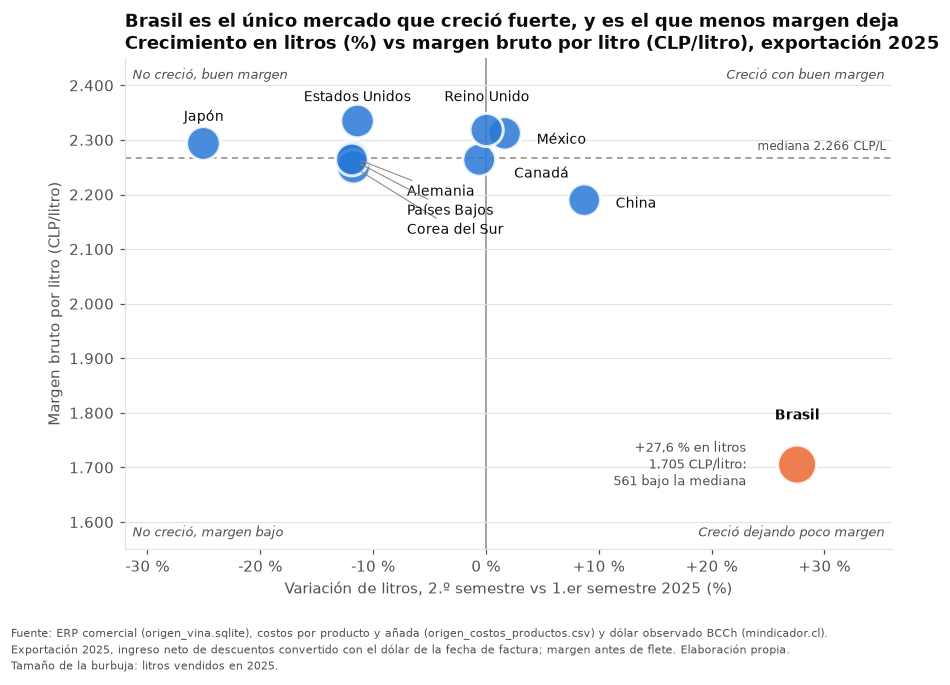

In [ ]:
pm = por_mercado.reset_index()
fig, ax = plt.subplots(figsize=(9, 5.8))

ax.axvline(0, color=GRIS, lw=1, zorder=1)
ax.axhline(MEDIANA, color=GRIS, lw=1, ls=(0, (4, 3)), zorder=1)

tam = pm["litros"] / pm["litros"].max() * 650
ax.scatter(
    pm["crecimiento_pct"], pm["margen_litro"], s=tam,
    c=[color_pais(p) for p in pm["pais"]], alpha=0.85,
    edgecolors="white", linewidths=2, zorder=3,
)

# Etiquetas en coordenadas de datos; el grupo que se superpone va a la derecha con línea guía
pos_etiqueta = {
    "Estados Unidos": (-11.4, 2378, "center"), "Japón": (-25.0, 2342, "center"),
    "Reino Unido": (0.1, 2378, "center"), "México": (4.5, 2300, "left"),
    "Canadá": (2.5, 2238, "left"), "China": (11.5, 2183, "left"),
    "Alemania": (-7.0, 2205, "left"), "Países Bajos": (-7.0, 2170, "left"),
    "Corea del Sur": (-7.0, 2135, "left"), "Brasil": (27.6, 1795, "center"),
}
con_guia = {"Alemania", "Países Bajos", "Corea del Sur"}
for r in pm.itertuples():
    xt, yt, ha = pos_etiqueta[r.pais]
    ax.annotate(
        r.pais, (r.crecimiento_pct, r.margen_litro), xytext=(xt, yt), textcoords="data",
        ha=ha, va="center", fontsize=9, color=TEXTO,
        fontweight="bold" if r.pais == "Brasil" else "normal",
        arrowprops=dict(arrowstyle="-", color=GRIS, lw=0.7, shrinkA=2, shrinkB=6) if r.pais in con_guia else None,
        zorder=4,
    )
fila_br = pm[pm["pais"].eq("Brasil")].iloc[0]
ax.text(
    fila_br["crecimiento_pct"] - 4.5, fila_br["margen_litro"],
    f"+{num(fila_br['crecimiento_pct'], 1)} % en litros\n{num(fila_br['margen_litro'])} CLP/litro:\n"
    f"{num(MEDIANA - fila_br['margen_litro'])} bajo la mediana",
    ha="right", va="center", fontsize=8.5, color=TEXTO_2,
)

# Rótulos de cuadrante
kw = dict(fontsize=8.5, color=TEXTO_2, style="italic")
ax.text(0.99, 0.98, "Creció con buen margen", transform=ax.transAxes, ha="right", va="top", **kw)
ax.text(0.99, 0.02, "Creció dejando poco margen", transform=ax.transAxes, ha="right", va="bottom", **kw)
ax.text(0.01, 0.98, "No creció, buen margen", transform=ax.transAxes, ha="left", va="top", **kw)
ax.text(0.01, 0.02, "No creció, margen bajo", transform=ax.transAxes, ha="left", va="bottom", **kw)

ax.set_xlim(-32, 36)
ax.set_ylim(1550, 2450)
ax.text(35.5, MEDIANA + 10, f"mediana {num(MEDIANA)} CLP/L", ha="right", va="bottom", fontsize=8, color=TEXTO_2)
ax.yaxis.set_major_formatter(miles)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:+.0f} %".replace("+0 %", "0 %")))
ax.set_xlabel("Variación de litros, 2.º semestre vs 1.er semestre 2025 (%)")
ax.set_ylabel("Margen bruto por litro (CLP/litro)")
ax.grid(axis="y")
ax.set_title("Brasil es el único mercado que creció fuerte, y es el que menos margen deja\n"
             "Crecimiento en litros (%) vs margen bruto por litro (CLP/litro), exportación 2025")
pie(fig, FUENTE + "\nTamaño de la burbuja: litros vendidos en 2025.")
plt.show()

### E2 · Margen bruto por litro por mercado

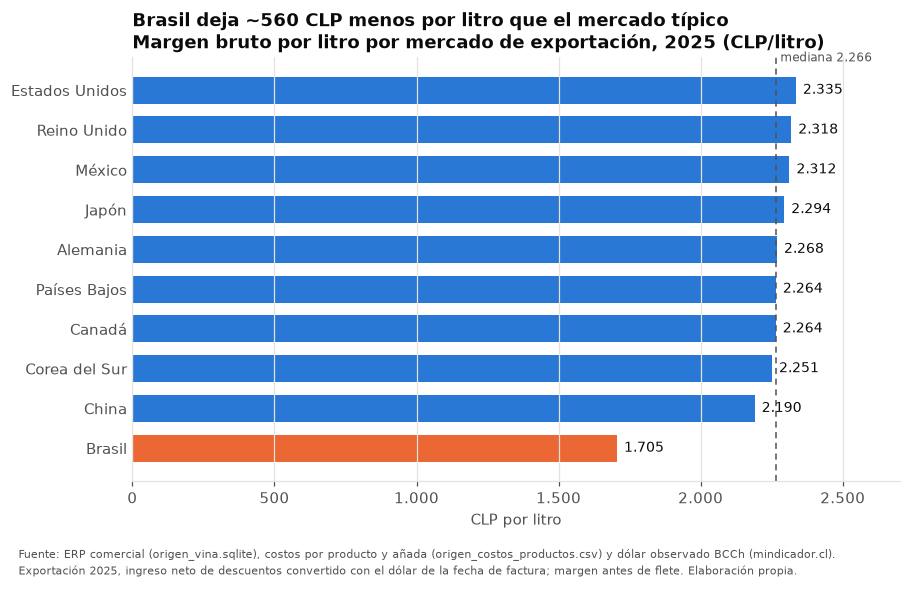

In [6]:
orden = por_mercado.sort_values("margen_litro")
fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.barh(orden.index, orden["margen_litro"], color=[color_pais(p) for p in orden.index], height=0.68)
for b, v in zip(barras, orden["margen_litro"]):
    ax.text(v + 25, b.get_y() + b.get_height() / 2, num(v), va="center", fontsize=9, color=TEXTO)
ax.axvline(MEDIANA, color=TEXTO_2, lw=1, ls=(0, (4, 3)))
ax.text(MEDIANA, len(orden) - 0.35, f" mediana {num(MEDIANA)}", fontsize=8, color=TEXTO_2, va="bottom")
ax.set_xlim(0, 2700)
ax.xaxis.set_major_formatter(miles)
ax.set_xlabel("CLP por litro")
ax.grid(axis="x")
ax.tick_params(axis="y", length=0)
ax.set_title("Brasil deja ~560 CLP menos por litro que el mercado típico\n"
             "Margen bruto por litro por mercado de exportación, 2025 (CLP/litro)")
pie(fig)
plt.show()

### E3 · Litros por trimestre: Brasil frente al mercado promedio

Brasil se compara con el **promedio de los otros 9 mercados** de exportación (misma unidad, mismo eje).

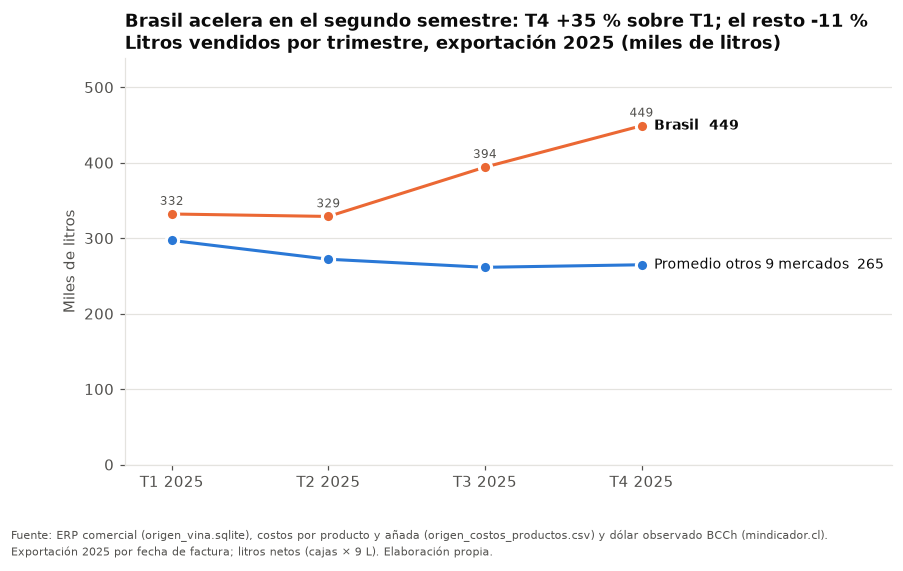

In [7]:
lt = fe.groupby(["trimestre", "pais"])["litros"].sum().unstack()
serie_br = lt["Brasil"] / 1000
serie_resto = lt.drop(columns="Brasil").mean(axis=1) / 1000

fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(lt.index))
ax.plot(x, serie_br, color=NARANJA, lw=2, marker="o", ms=8, markeredgecolor="white", markeredgewidth=2, zorder=3)
ax.plot(x, serie_resto, color=AZUL, lw=2, marker="o", ms=8, markeredgecolor="white", markeredgewidth=2, zorder=3)
ax.text(x[-1] + 0.08, serie_br.iloc[-1], f"Brasil  {num(serie_br.iloc[-1])}", va="center", color=TEXTO, fontsize=9, fontweight="bold")
ax.text(x[-1] + 0.08, serie_resto.iloc[-1], f"Promedio otros 9 mercados  {num(serie_resto.iloc[-1])}", va="center", color=TEXTO, fontsize=9)
for xi, v in zip(x, serie_br):
    ax.text(xi, v + 12, num(v), ha="center", fontsize=8, color=TEXTO_2)
ax.set_xticks(x, [f"{t} 2025" for t in lt.index])
ax.set_xlim(-0.3, 4.6)
ax.set_ylim(0, max(serie_br.max(), serie_resto.max()) * 1.2)
ax.yaxis.set_major_formatter(miles)
ax.set_ylabel("Miles de litros")
ax.grid(axis="y")
var_br = (serie_br.iloc[-1] / serie_br.iloc[0] - 1) * 100
var_resto = (serie_resto.iloc[-1] / serie_resto.iloc[0] - 1) * 100
ax.set_title(f"Brasil acelera en el segundo semestre: T4 {var_br:+.0f} % sobre T1; el resto {var_resto:+.0f} %\n"
             "Litros vendidos por trimestre, exportación 2025 (miles de litros)".replace(".", ","))
pie(fig, FUENTE.split("\n")[0] + "\nExportación 2025 por fecha de factura; litros netos (cajas × 9 L). Elaboración propia.")
plt.show()

### E4 · Descuento comercial por mercado (la causa del margen bajo)

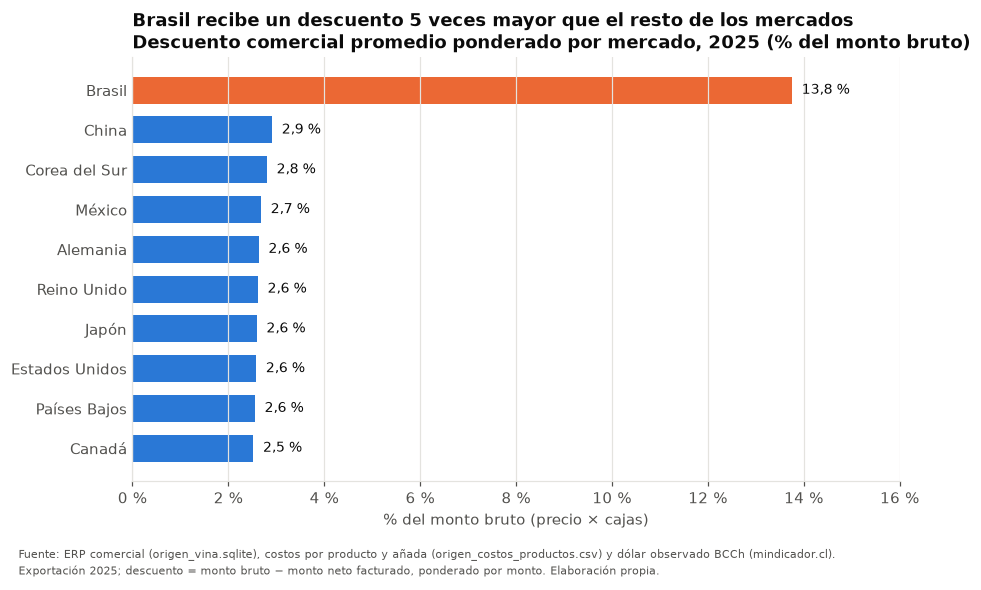

In [8]:
orden = por_mercado.sort_values("descuento_pct")
fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.barh(orden.index, orden["descuento_pct"], color=[color_pais(p) for p in orden.index], height=0.68)
for b, v in zip(barras, orden["descuento_pct"]):
    ax.text(v + 0.2, b.get_y() + b.get_height() / 2, f"{num(v, 1)} %", va="center", fontsize=9, color=TEXTO)
ax.set_xlim(0, 16)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0f} %"))
ax.set_xlabel("% del monto bruto (precio × cajas)")
ax.grid(axis="x")
ax.tick_params(axis="y", length=0)
ax.set_title("Brasil recibe un descuento 5 veces mayor que el resto de los mercados\n"
             "Descuento comercial promedio ponderado por mercado, 2025 (% del monto bruto)")
pie(fig, FUENTE.split("\n")[0] + "\nExportación 2025; descuento = monto bruto − monto neto facturado, ponderado por monto. Elaboración propia.")
plt.show()

### D1 · Sensibilidad a la fecha del dólar (para la Sección D)

No cuenta entre las visualizaciones de E; respalda la ficha de la métrica.

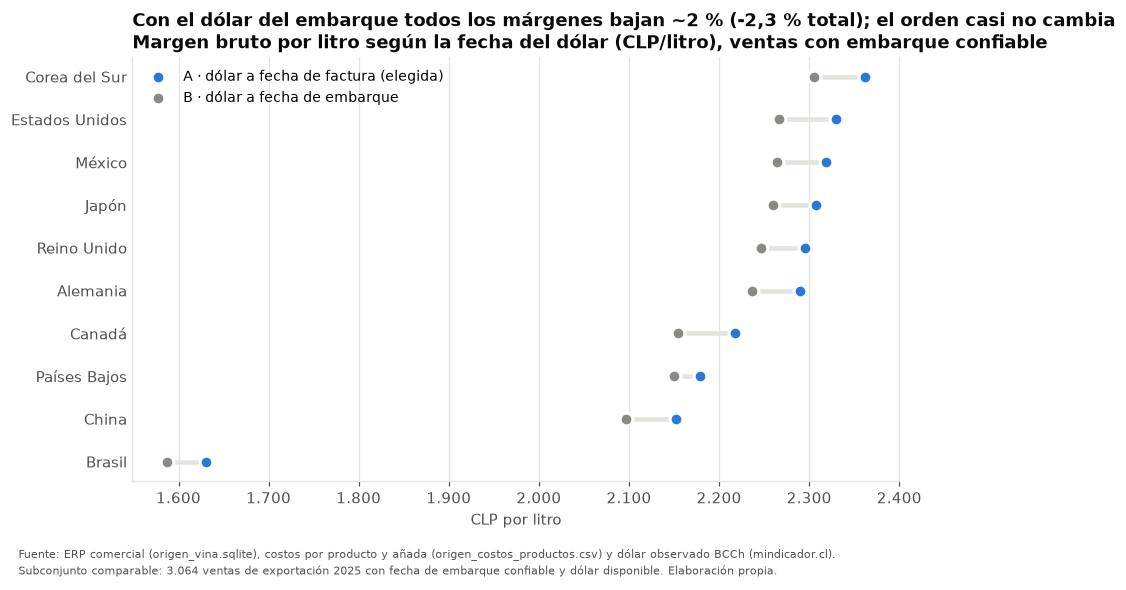

In [9]:
c = comp.sort_values("CLP_litro_Def_A")
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(c))
ax.hlines(y, c["CLP_litro_Def_B"], c["CLP_litro_Def_A"], color=GRILLA, lw=3, zorder=1)
ax.scatter(c["CLP_litro_Def_A"], y, s=70, color=AZUL, edgecolors="white", linewidths=2, zorder=3, label="A · dólar a fecha de factura (elegida)")
ax.scatter(c["CLP_litro_Def_B"], y, s=70, color=GRIS, edgecolors="white", linewidths=2, zorder=3, label="B · dólar a fecha de embarque")
ax.set_yticks(y, c["pais"])
ax.tick_params(axis="y", length=0)
ax.xaxis.set_major_formatter(miles)
ax.set_xlabel("CLP por litro")
ax.grid(axis="x")
ax.legend(loc="upper left", frameon=False, fontsize=9)
dif_total = (mg_total_b / mg_total_a - 1) * 100
ax.set_title(f"Con el dólar del embarque todos los márgenes bajan ~2 % ({num(dif_total, 1)} % total); el orden casi no cambia\n"
             "Margen bruto por litro según la fecha del dólar (CLP/litro), ventas con embarque confiable")
pie(fig, FUENTE.split("\n")[0] + f"\nSubconjunto comparable: {num(len(fact_export_b))} ventas de exportación 2025 con fecha de embarque confiable y dólar disponible. Elaboración propia.")
plt.show()

## 4. Caso de negocio en pesos

Tres preguntas:

1. **¿Cuánto margen deja de generar Brasil** frente a un mercado típico (la mediana)?
2. **¿Cuánto de eso es el descuento especial?** Se recalcula Brasil con el descuento promedio ponderado del resto de la exportación, manteniendo precio de lista, mix y volumen.
3. **¿Cuánto volumen podría perder Brasil** con un descuento normal antes de dejar menos margen total que hoy? Es el punto de equilibrio de la decisión.

In [10]:
br = por_mercado.loc["Brasil"]
resto = por_mercado.drop(index="Brasil")
desc_resto_pct = resto["descuento_clp"].sum() / resto["bruto_clp"].sum() * 100
desc_br_pct = br["descuento_pct"]

# 1. Brecha contra la mediana
brecha_litro = MEDIANA - br["margen_litro"]
brecha_total = brecha_litro * br["litros"]

# 2. Descuento extra de Brasil, en pesos
descuento_extra = br["bruto_clp"] * (desc_br_pct - desc_resto_pct) / 100
margen_br_contraf = br["margen_clp"] + descuento_extra
margen_litro_contraf = margen_br_contraf / br["litros"]

# 3. Punto de equilibrio: litros con descuento normal que igualan el margen actual
litros_equilibrio = br["margen_clp"] / margen_litro_contraf
perdida_vol_tolerable = (1 - litros_equilibrio / br["litros"]) * 100

# Crecimiento de Brasil entre semestres y lo que dejó
litros_extra_s2 = br["S2"] - br["S1"]
margen_sem = fe[fe["pais"].eq("Brasil")].assign(semestre=lambda d: np.where(d["fecha"].dt.month <= 6, "S1", "S2"))
margen_sem = margen_sem.groupby("semestre").agg(m=("margen_clp", "sum"), l=("litros", "sum"))
margen_sem["m_litro"] = margen_sem["m"] / margen_sem["l"]

# Peso de Brasil en la exportación
part_litros = br["litros"] / por_mercado["litros"].sum() * 100
part_margen = br["margen_clp"] / por_mercado["margen_clp"].sum() * 100

MM = 1e6
caso = pd.DataFrame(
    [
        ("Litros Brasil 2025", num(br["litros"]), "L"),
        ("Margen bruto Brasil 2025", num(br["margen_clp"] / MM), "MM CLP"),
        ("Margen por litro Brasil", num(br["margen_litro"]), "CLP/L"),
        ("Mediana de los mercados de exportación", num(MEDIANA), "CLP/L"),
        ("Brecha por litro vs mediana", num(brecha_litro), "CLP/L"),
        ("1. Margen que Brasil deja de generar vs mediana", num(brecha_total / MM), "MM CLP/año"),
        ("Descuento Brasil", num(desc_br_pct, 1), "% del bruto"),
        ("Descuento resto de exportación", num(desc_resto_pct, 1), "% del bruto"),
        ("2. Costo del descuento extra de Brasil", num(descuento_extra / MM), "MM CLP/año"),
        ("   Margen por litro Brasil con descuento normal", num(margen_litro_contraf), "CLP/L"),
        ("   Parte de la brecha explicada por el descuento", num(descuento_extra / brecha_total * 100), "%"),
        ("3. Volumen que Brasil podría perder sin bajar su margen total", num(perdida_vol_tolerable, 1), "% de los litros"),
        ("Crecimiento Brasil S2 vs S1", f"+{num(br['crecimiento_pct'], 1)}", "%"),
        ("Litros adicionales S2 vs S1", num(litros_extra_s2), "L"),
        ("Margen por litro Brasil S1 → S2", f"{num(margen_sem.loc['S1','m_litro'])} → {num(margen_sem.loc['S2','m_litro'])}", "CLP/L"),
        ("Brasil: % de los litros de exportación", num(part_litros, 1), "%"),
        ("Brasil: % del margen de exportación", num(part_margen, 1), "%"),
    ],
    columns=["Cifra", "Valor", "Unidad"],
)
print(caso.to_string(index=False))

                                                        Cifra         Valor          Unidad
                                           Litros Brasil 2025     1.503.855               L
                                     Margen bruto Brasil 2025         2.564          MM CLP
                                      Margen por litro Brasil         1.705           CLP/L
                       Mediana de los mercados de exportación         2.266           CLP/L
                                  Brecha por litro vs mediana           561           CLP/L
              1. Margen que Brasil deja de generar vs mediana           843      MM CLP/año
                                             Descuento Brasil          13,8     % del bruto
                               Descuento resto de exportación           2,7     % del bruto
                       2. Costo del descuento extra de Brasil           784      MM CLP/año
                 Margen por litro Brasil con descuento normal         2.226     

## 5. Cobertura de datos

Qué porcentaje de los registros de la fuente entra al cálculo y por qué queda fuera el resto.

In [11]:
reg_fuente = len(stg_ventas)
duplicados = reg_fuente - len(fact_venta)
nacionales = int((fact_venta["mercado_id"] == 1).sum())
analizados = len(fact_export)
sin_costo_ni_tc = int(fact_export[["ingreso_neto_clp_fecha_venta", "costo_total_clp"]].isna().any(axis=1).sum())

cobertura = pd.DataFrame(
    [
        ("Registros de venta en la fuente", reg_fuente, 100.0, ""),
        ("− Registros duplicados (venta_id repetido)", -duplicados, -duplicados / reg_fuente * 100, "calidad"),
        ("− Ventas nacionales (Chile)", -nacionales, -nacionales / reg_fuente * 100, "fuera del alcance: la pregunta es de exportación"),
        ("− Exportación sin costo o sin dólar", -sin_costo_ni_tc, -sin_costo_ni_tc / reg_fuente * 100, "costos completados por tier y añada"),
        ("= Ventas en el análisis", analizados, analizados / reg_fuente * 100, ""),
    ],
    columns=["Concepto", "Registros", "% de la fuente", "Motivo"],
)
excluido_pct = 100 - analizados / reg_fuente * 100
excluido_calidad_pct = duplicados / reg_fuente * 100
print(f"Quedan fuera {num(excluido_pct, 1)} % de los registros: {num(nacionales / reg_fuente * 100, 1)} % por alcance (Chile) "
      f"y {num(excluido_calidad_pct, 1)} % por calidad (duplicados).")
print(f"Dentro de la exportación entra el {num(100 - sin_costo_ni_tc / analizados * 100, 1)} % de las ventas limpias.")
print()
print(cobertura.assign(**{"Registros": cobertura["Registros"].map(num), "% de la fuente": cobertura["% de la fuente"].map(lambda v: num(v, 1))}).to_string(index=False))

Quedan fuera 23,3 % de los registros: 22,3 % por alcance (Chile) y 1,0 % por calidad (duplicados).
Dentro de la exportación entra el 100,0 % de las ventas limpias.

                                  Concepto Registros % de la fuente                                           Motivo
           Registros de venta en la fuente    13.968          100,0                                                 
− Registros duplicados (venta_id repetido)      -138           -1,0                                          calidad
               − Ventas nacionales (Chile)    -3.115          -22,3 fuera del alcance: la pregunta es de exportación
       − Exportación sin costo o sin dólar         0            0,0              costos completados por tier y añada
                   = Ventas en el análisis    10.715           76,7                                                 


## 6. Texto de la Sección E



## E. Evidencia, caso de negocio y recomendación

### E.1 Visualizaciones

- **Figura E1.** Crecimiento en litros (S2 vs S1 2025, %) vs margen bruto por litro (CLP/litro): responde la pregunta en una imagen.
- **Figura E2.** Margen bruto por litro por mercado de exportación, 2025 (CLP/litro).
- **Figura E3.** Litros por trimestre, Brasil vs promedio de los otros 9 mercados (miles de litros).
- **Figura E4.** Descuento comercial promedio por mercado, 2025 (% del monto bruto).

### Respuesta a la pregunta

De los 10 mercados de exportación, **4 crecieron en litros** entre el primer y el segundo semestre de 2025:

- **Crecieron con buen margen** (sobre la mediana de 2.266 CLP/litro): México (+1,7 %, 2.312 CLP/L), Reino Unido (+0,1 %, 2.318 CLP/L).
- **Crecieron dejando poco margen:** Brasil (+27,6 %, 1.705 CLP/L), China (+8,7 %, 2.190 CLP/L).

Los otros 6 mercados no crecieron en el período.

**Brasil es el caso que importa.** Es el mercado que más creció (+27,6 % en litros, el más grande de la exportación con el 13,2 % de los litros) y el que menos deja por litro: 1.705 CLP/litro, 561 bajo la mediana. Aporta el 13,2 % del volumen exportado pero solo el 10,3 % del margen. El mix de productos de Brasil es similar al del resto; lo que explica la diferencia es su descuento promedio de 13,8 %, frente a 2,7 % en el resto de la exportación.

### E.2 Caso de negocio en pesos

- **Brecha:** a un margen por litro igual a la mediana, Brasil habría dejado **843 millones de pesos más** en 2025.
- **Costo del descuento especial:** el descuento sobre lo que reciben los demás mercados le costó a la viña **784 millones de pesos en 2025** (93 % de la brecha). Con un descuento normal, Brasil dejaría 2.226 CLP/litro, en línea con el resto.
- **Punto de equilibrio:** con un descuento normal, Brasil podría vender hasta **23,4 % menos litros** y aun así dejar el mismo margen total que dejó en 2025.

### E.3 Recomendación a la gerencia

1. **Revisar el descuento especial de Brasil antes de renovarlo.** Fue una decisión del directorio para ganar volumen, y lo logró, pero cada litro vendido en Brasil deja 561 pesos menos que en un mercado típico: unos 784 millones de pesos al año. Proponemos bajarlo gradualmente hacia el nivel del resto (≈2,7 %) o condicionarlo a metas de volumen, y medir trimestralmente cuánto volumen se pierde. Mientras la caída de volumen sea menor a 23 %, Brasil deja más margen que hoy.
2. **Poner el foco comercial en México, Reino Unido**, que crecieron sin sacrificar margen.
3. **Revisar el mix de China**, que creció (+8,7 %) con margen bajo la mediana: el 41,7 % de sus litros es varietal, la proporción más alta de la exportación.
4. **Medir los mercados en margen por litro en pesos, no solo en litros.** El reporte mensual que hoy se arma en Excel debería incluir esta métrica por mercado, con el ingreso después de descuento y el dólar de la fecha de factura, que es como Finanzas reconoce el ingreso.

*Alcance:* el margen es antes de flete y seguro (no están en las fuentes). La proporción de litros en CIF es similar entre mercados (36 % a 42 %, cuaderno 02), por lo que ese costo no cambiaría el orden entre ellos. El crecimiento compara semestres de un mismo año, por lo que incluye estacionalidad.

### E.4 Cobertura de datos

**76,7 % de los registros de venta de la fuente entra al análisis** (10.715 de 13.968). Queda fuera el 23,3 %: 22,3 % son ventas nacionales (fuera del alcance de la pregunta) y 1,0 % son registros duplicados. Dentro de la exportación, el 100 % de las ventas tiene costo y tipo de cambio; el 71,4 % no tiene fecha de embarque confiable, lo que no afecta la métrica elegida (dólar a fecha de factura).
